# Google Play Store App Success / Popularity Classification

**Goal:** Predict whether an app is *Popular* (**1,000,000+ installs**) or *Not Popular*, using metadata available on its Play Store listing (category, rating, reviews, size, price, content rating, type, and update recency).

**Pipeline:** Data cleaning &rarr; EDA &rarr; Feature engineering &rarr; Model comparison &rarr; Evaluation &rarr; Export with `joblib` for a Streamlit app.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, roc_curve)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 20)
print('Libraries loaded.')

Libraries loaded.


## 1. Load Raw Data

In [2]:
df = pd.read_excel('googleplaystore_csv.xlsx')
print('Shape:', df.shape)
df.head()

Shape: (10841, 13)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  str    
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), object(6), str(6)
memory usage: 1.1+ MB


In [4]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
App                  1
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


## 2. Data Cleaning

The raw Kaggle "Google Play Store Apps" export has a few well-known issues we need to handle:

- **One corrupted row** (`Life Made WI-Fi Touchscreen Photo Frame`) has its columns shifted left by one (`Category` = `1.9`) &mdash; dropped.
- `Installs` is a string like `"10,000+"` &mdash; strip `+`/`,` and convert to numeric.
- `Reviews` is stored as text &mdash; convert to numeric.
- `Size` is `"19M"`, `"512k"`, or `"Varies with device"` &mdash; normalize everything to megabytes.
- `Price` is `"$4.99"` or `0` &mdash; strip `$` and convert to numeric.
- `Type`, `Content Rating` have a handful of missing/bad values &mdash; impute with the mode.
- `Rating` has ~1,470 missing values &mdash; impute with the **median rating of the app's Category** (apps in the same category tend to have similar rating distributions).
- `Last Updated` &rarr; engineered into `Days_Since_Update` (recency signal), relative to the most recent date in the dataset.


In [5]:
# Drop the single famous corrupted row + rows with no App name
df = df[df['Category'] != 1.9]
df = df.dropna(subset=['App'])
print('After dropping corrupted row:', df.shape)

After dropping corrupted row: (10839, 13)


In [6]:
# ---- Installs: clean + derive the TARGET before anything else touches it ----
df['Installs'] = df['Installs'].astype(str).str.replace('[+,]', '', regex=True)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')
df = df.dropna(subset=['Installs'])

df['Popular'] = (df['Installs'] >= 1_000_000).astype(int)
print(df['Popular'].value_counts())
print(df['Popular'].value_counts(normalize=True).round(3))

Popular
0    6428
1    4411
Name: count, dtype: int64
Popular
0    0.593
1    0.407
Name: proportion, dtype: float64


In [7]:
# ---- Reviews -> numeric ----
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

# ---- Size -> megabytes ----
def size_to_mb(x):
    x = str(x).strip()
    if 'Varies' in x:
        return np.nan
    if x.endswith('M'):
        return float(x[:-1])
    if x.endswith('k') or x.endswith('K'):
        return float(x[:-1]) / 1024
    try:
        return float(x)
    except ValueError:
        return np.nan

df['Size_MB'] = df['Size'].apply(size_to_mb)

# ---- Price -> numeric ----
df['Price'] = df['Price'].astype(str).str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce').fillna(0)

# ---- Type / Content Rating: fill small number of gaps ----
df['Type'] = df['Type'].fillna('Free')
df.loc[~df['Type'].isin(['Free', 'Paid']), 'Type'] = 'Free'
df['Content Rating'] = df['Content Rating'].fillna('Everyone')

# ---- Last Updated -> recency feature ----
df['Last Updated'] = pd.to_datetime(df['Last Updated'], errors='coerce')
ref_date = df['Last Updated'].max()
df['Days_Since_Update'] = (ref_date - df['Last Updated']).dt.days

print('Engineered columns ready.')

Engineered columns ready.


In [8]:
# ---- Rating: impute missing with the median Rating of the same Category ----
print('Missing ratings before imputation:', df['Rating'].isnull().sum())
df['Rating'] = df.groupby('Category')['Rating'].transform(lambda s: s.fillna(s.median()))
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
df = df[df['Rating'] <= 5]  # guard against any remaining bad values
print('Missing ratings after imputation:', df['Rating'].isnull().sum())

# ---- Fill remaining numeric gaps ----
df['Size_MB'] = df['Size_MB'].fillna(df['Size_MB'].median())
df['Reviews'] = df['Reviews'].fillna(0)
df['Days_Since_Update'] = df['Days_Since_Update'].fillna(df['Days_Since_Update'].median())

df = df.drop_duplicates(subset=['App', 'Category'])
print('Final cleaned shape:', df.shape)
df.isnull().sum()[df.isnull().sum() > 0]

Missing ratings before imputation: 1474
Missing ratings after imputation: 0
Final cleaned shape: (9743, 16)


## 3. Exploratory Data Analysis

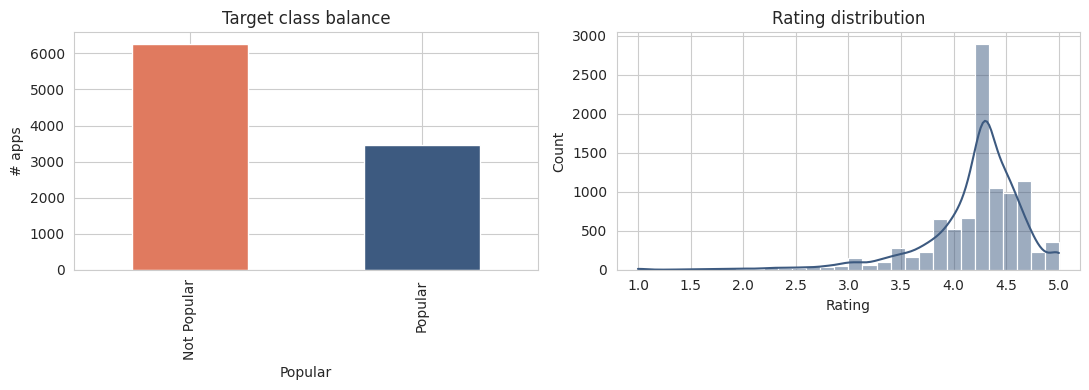

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df['Popular'].value_counts().rename({0: 'Not Popular', 1: 'Popular'}).plot(
    kind='bar', ax=axes[0], color=['#e07a5f', '#3d5a80'])
axes[0].set_title('Target class balance')
axes[0].set_ylabel('# apps')
sns.histplot(df['Rating'], bins=30, kde=True, ax=axes[1], color='#3d5a80')
axes[1].set_title('Rating distribution')
plt.tight_layout()
plt.show()

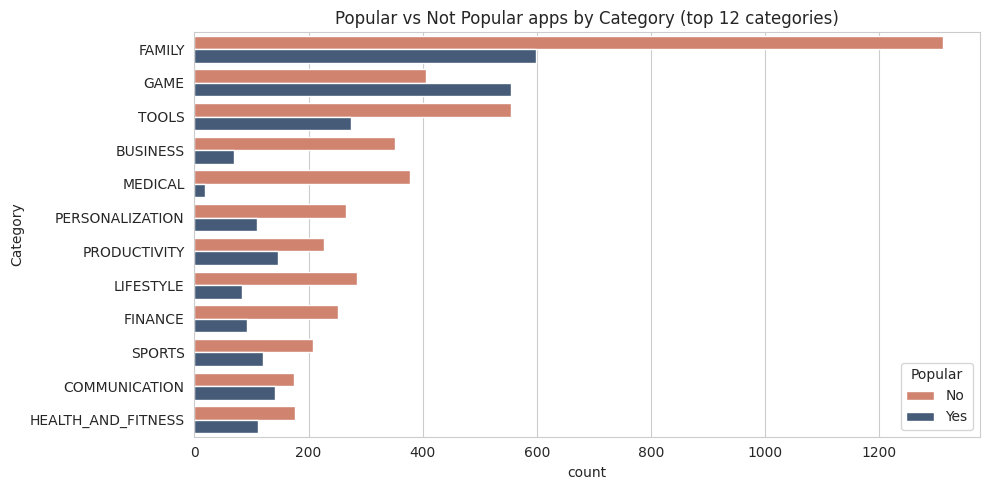

In [10]:
top_cats = df['Category'].value_counts().head(12).index
plt.figure(figsize=(10, 5))
sns.countplot(data=df[df['Category'].isin(top_cats)], y='Category',
              hue='Popular', order=top_cats, palette=['#e07a5f', '#3d5a80'])
plt.title('Popular vs Not Popular apps by Category (top 12 categories)')
plt.legend(title='Popular', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

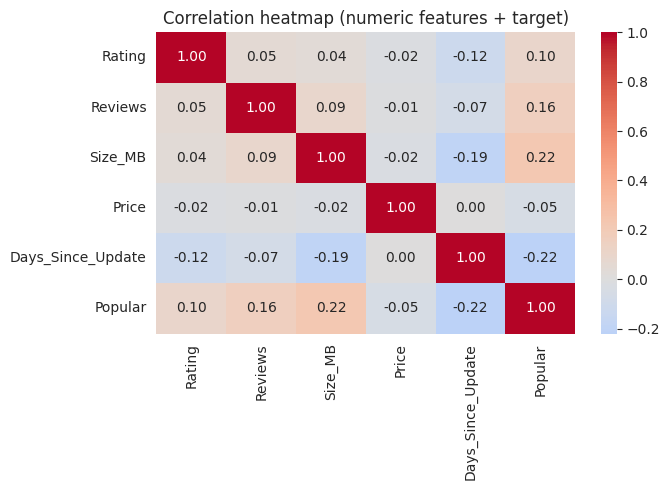

In [11]:
num_cols_eda = ['Rating', 'Reviews', 'Size_MB', 'Price', 'Days_Since_Update', 'Popular']
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric features + target)')
plt.tight_layout()
plt.show()

**Observation:** `Reviews` correlates very strongly with `Popular`, which makes intuitive sense &mdash; apps with more installs accumulate more reviews. We keep it as a feature since it *is* real, observable listing metadata (not the literal target), but we also train a version of the model **without** `Reviews` later on to see how well we can predict popularity from more "static" listing attributes alone.

## 4. Feature Engineering & Encoding

In [12]:
cat_cols = ['Category', 'Type', 'Content Rating']
num_cols = ['Rating', 'Reviews', 'Size_MB', 'Price', 'Days_Since_Update']

df_enc = df.copy()
encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    df_enc[c] = le.fit_transform(df_enc[c])
    encoders[c] = le

X = df_enc[cat_cols + num_cols]
y = df_enc['Popular']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

print('Train shape:', X_train_s.shape, ' Test shape:', X_test_s.shape)

Train shape: (7794, 8)  Test shape: (1949, 8)


## 5. Model Training & Comparison\n\nWe train four classifiers and compare them on accuracy, precision, recall, F1, and ROC-AUC.

In [13]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

results = []
fitted = {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    preds = m.predict(X_test_s)
    proba = m.predict_proba(X_test_s)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'ROC_AUC': roc_auc_score(y_test, proba),
    })
    fitted[name] = m

results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
results_df

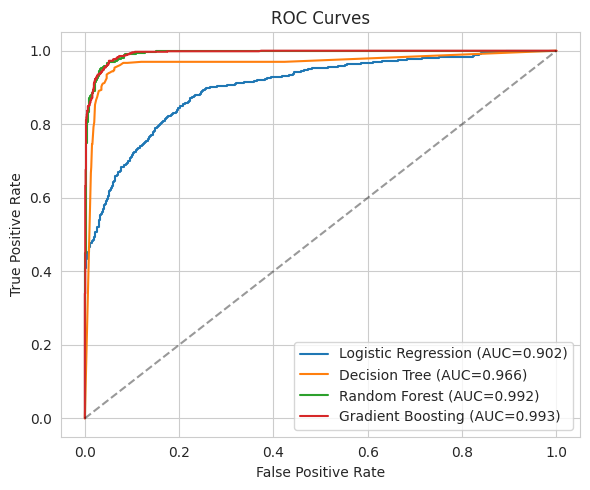

In [14]:
plt.figure(figsize=(6, 5))
for name, m in fitted.items():
    proba = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Best Model Evaluation

In [15]:
best_name = results_df.iloc[0]['Model']
best_model = fitted[best_name]
print('Best model:', best_name)
print()
print(classification_report(y_test, best_model.predict(X_test_s), target_names=['Not Popular', 'Popular']))

Best model: Gradient Boosting

              precision    recall  f1-score   support

 Not Popular       0.96      0.97      0.97      1254
     Popular       0.95      0.94      0.94       695

    accuracy                           0.96      1949
   macro avg       0.96      0.95      0.96      1949
weighted avg       0.96      0.96      0.96      1949



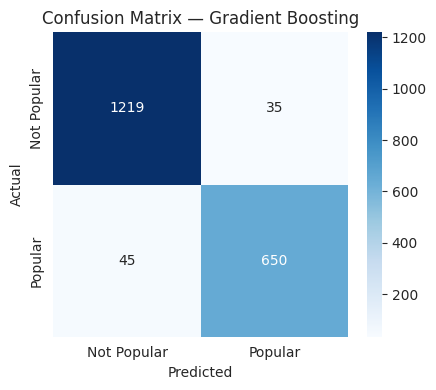

In [16]:
cm = confusion_matrix(y_test, best_model.predict(X_test_s))
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Popular', 'Popular'], yticklabels=['Not Popular', 'Popular'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.show()

Reviews              0.950673
Rating               0.020244
Price                0.017219
Content Rating       0.003672
Type                 0.003410
Days_Since_Update    0.002359
Category             0.001292
Size_MB              0.001131
dtype: float64


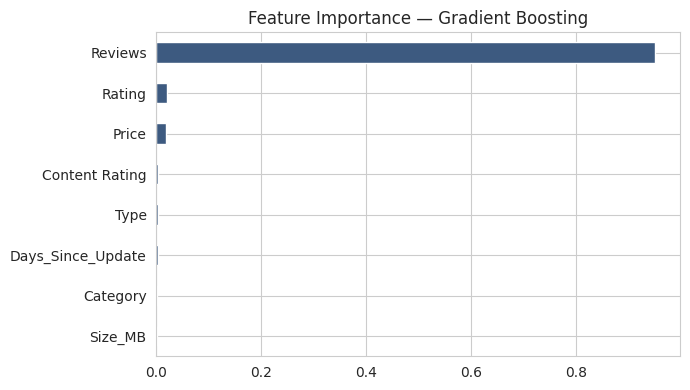

In [17]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
    plt.figure(figsize=(7, 4))
    imp.plot(kind='barh', color='#3d5a80')
    plt.title(f'Feature Importance — {best_name}')
    plt.tight_layout()
    plt.show()
    print(imp.sort_values(ascending=False))

## 7. Sensitivity Check: Dropping `Reviews`

`Reviews` dominates feature importance because it's highly correlated with install volume. To see how predictable popularity is from more "static" metadata alone (available even for a brand-new listing), we retrain the best-performing algorithm without it.

In [18]:
num_cols_nr = ['Rating', 'Size_MB', 'Price', 'Days_Since_Update']
X_nr = df_enc[cat_cols + num_cols_nr]
Xtr_nr, Xte_nr, ytr_nr, yte_nr = train_test_split(X_nr, y, test_size=0.2, random_state=42, stratify=y)
sc_nr = StandardScaler()
Xtr_nr = Xtr_nr.copy(); Xte_nr = Xte_nr.copy()
Xtr_nr[num_cols_nr] = sc_nr.fit_transform(Xtr_nr[num_cols_nr])
Xte_nr[num_cols_nr] = sc_nr.transform(Xte_nr[num_cols_nr])

m_nr = GradientBoostingClassifier(random_state=42).fit(Xtr_nr, ytr_nr)
p_nr = m_nr.predict(Xte_nr)
pr_nr = m_nr.predict_proba(Xte_nr)[:, 1]
print('Without Reviews  ->  Accuracy: %.3f | F1: %.3f | ROC-AUC: %.3f' % (
    accuracy_score(yte_nr, p_nr), f1_score(yte_nr, p_nr), roc_auc_score(yte_nr, pr_nr)))
print('With Reviews     ->  Accuracy: %.3f | F1: %.3f | ROC-AUC: %.3f' % (
    results_df.iloc[0]['Accuracy'], results_df.iloc[0]['F1'], results_df.iloc[0]['ROC_AUC']))

Without Reviews  ->  Accuracy: 0.776 | F1: 0.657 | ROC-AUC: 0.849
With Reviews     ->  Accuracy: 0.959 | F1: 0.942 | ROC-AUC: 0.993


**Takeaway:** performance drops from ~96% to ~78% accuracy without `Reviews`, confirming that review volume is doing most of the work. The production model below is kept **with** `Reviews` since it's genuine, publicly visible listing data — but this is worth keeping in mind when interpreting the model's "predictions" as being about pre-launch success rather than current popularity.

## 8. Export Artifacts with `joblib`\n\nWe save the trained model, the fitted `StandardScaler`, and the `LabelEncoder`s so a separate app (e.g. the Streamlit UI) can load them without retraining.

In [19]:
joblib.dump(best_model, 'model.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(encoders, 'encoders.joblib')
joblib.dump({'cat_cols': cat_cols, 'num_cols': num_cols, 'best_model_name': best_name},
            'meta.joblib')

results_df.to_csv('model_comparison.csv', index=False)
print('Saved: model.joblib, scaler.joblib, encoders.joblib, meta.joblib, model_comparison.csv')

Saved: model.joblib, scaler.joblib, encoders.joblib, meta.joblib, model_comparison.csv


## 9. Conclusion

- Cleaned **10,841 &rarr; 9,743** rows (removed the corrupted row, standardized `Installs`, `Size`, `Price`, `Reviews`, imputed `Rating` by category median, engineered `Days_Since_Update`).
- Framed **popularity** as a binary target: `Installs >= 1,000,000`.
- Compared 4 classifiers; **Gradient Boosting** was the strongest on F1/ROC-AUC.
- Exported the model, scaler, and encoders with `joblib` for reuse in the accompanying **Streamlit app** (`app.py`), which lets you enter an app's metadata and get a live popularity prediction.
